<a href="https://colab.research.google.com/github/andi-wahyudi/student-performance-predictor/blob/main/notebooks/03_training_evaluation_student_performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import zipfile, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Library berhasil diimpor.")

Library berhasil diimpor.


In [ ]:
from google.colab import files
uploaded = files.upload()
zip_names = [n for n in uploaded if n.lower().endswith(".zip")]
if not zip_names:
    raise FileNotFoundError("Upload preprocessing_outputs.zip dari Tahap 2.")

DATA_DIR = Path("/content/preprocessing_stage2")
DATA_DIR.mkdir(exist_ok=True)
with zipfile.ZipFile(zip_names[0], "r") as z:
    z.extractall(DATA_DIR)

print("File hasil ekstraksi:")
for p in sorted(DATA_DIR.iterdir()):
    print(p.name)

Saving preprocessing_outputs.zip to preprocessing_outputs.zip
File hasil ekstraksi:
matematika_preprocessor.joblib
matematika_test.csv
matematika_train.csv
portugis_preprocessor.joblib
portugis_test.csv
portugis_train.csv


In [ ]:
def load_subject(prefix):
    train_path = DATA_DIR / f"{prefix}_train.csv"
    test_path = DATA_DIR / f"{prefix}_test.csv"
    prep_path = DATA_DIR / f"{prefix}_preprocessor.joblib"
    for p in [train_path, test_path, prep_path]:
        if not p.exists():
            raise FileNotFoundError(f"File tidak ditemukan: {p.name}")

    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)
    prep = joblib.load(prep_path)
    X_train, y_train = train_df.drop(columns=["G3"]), train_df["G3"]
    X_test, y_test = test_df.drop(columns=["G3"]), test_df["G3"]
    return X_train, X_test, y_train, y_test, prep

mat = load_subject("matematika")
por = load_subject("portugis")

for name, data in [("Matematika", mat), ("Bahasa Portugis", por)]:
    Xtr, Xte, ytr, yte, prep = data
    print(name, "| train:", Xtr.shape, "| test:", Xte.shape,
          "| G1/G2 tersedia:", "G1" in Xtr and "G2" in Xtr)

Matematika | train: (316, 32) | test: (79, 32) | G1/G2 tersedia: True
Bahasa Portugis | train: (519, 32) | test: (130, 32) | G1/G2 tersedia: True


In [ ]:
def transform_subject(data):
    X_train, X_test, y_train, y_test, prep = data
    return prep.transform(X_train), prep.transform(X_test), y_train, y_test, prep

mat_ready = transform_subject(mat)
por_ready = transform_subject(por)

for name, data in [("Matematika", mat_ready), ("Bahasa Portugis", por_ready)]:
    print(name, "train:", data[0].shape, "test:", data[1].shape)

Matematika train: (316, 58) test: (79, 58)
Bahasa Portugis train: (519, 58) test: (130, 58)


In [ ]:
def build_models():
    return {
        "Dummy Baseline": DummyRegressor(strategy="mean"),
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(
            n_estimators=200, min_samples_leaf=2,
            random_state=42, n_jobs=-1
        )
    }

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

def train_evaluate(data, subject):
    Xtr, Xte, ytr, yte, prep = data
    models, preds, rows = {}, {}, []
    for name, model in build_models().items():
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        models[name], preds[name] = model, pred
        rows.append({"Mata Pelajaran": subject, "Model": name, **evaluate(yte, pred)})
        print(subject, "|", name, "|", evaluate(yte, pred))
    return pd.DataFrame(rows), models, preds

In [ ]:
results_mat, models_mat, preds_mat = train_evaluate(mat_ready, "Matematika")
display(results_mat.round(4))

Matematika | Dummy Baseline | {'MAE': 3.64585002403461, 'RMSE': np.float64(4.550180652162387), 'R2': -0.009709643515769084}
Matematika | Linear Regression | {'MAE': 1.64666561971475, 'RMSE': np.float64(2.3783697847961367), 'R2': 0.7241341236974022}
Matematika | Random Forest | {'MAE': 1.2114741903665953, 'RMSE': np.float64(2.041505310621138), 'R2': 0.7967454608219784}


,Mata Pelajaran,Model,MAE,RMSE,R2
0,Matematika,Dummy Baseline,3.6459,4.5502,-0.0097
1,Matematika,Linear Regression,1.6467,2.3784,0.7241
2,Matematika,Random Forest,1.2115,2.0415,0.7967


In [ ]:
results_por, models_por, preds_por = train_evaluate(por_ready, "Bahasa Portugis")
display(results_por.round(4))

Bahasa Portugis | Dummy Baseline | {'MAE': 2.3946050096339113, 'RMSE': np.float64(3.1725903070595547), 'R2': -0.032159804579835916}
Bahasa Portugis | Linear Regression | {'MAE': 0.765059768275826, 'RMSE': np.float64(1.2148700573987046), 'R2': 0.8486513286537314}
Bahasa Portugis | Random Forest | {'MAE': 0.7211412393162395, 'RMSE': np.float64(1.2089110757994177), 'R2': 0.8501324287194514}


,Mata Pelajaran,Model,MAE,RMSE,R2
0,Bahasa Portugis,Dummy Baseline,2.3946,3.1726,-0.0322
1,Bahasa Portugis,Linear Regression,0.7651,1.2149,0.8487
2,Bahasa Portugis,Random Forest,0.7211,1.2089,0.8501


In [ ]:
results_all = pd.concat([results_mat, results_por], ignore_index=True)
display(results_all.sort_values(["Mata Pelajaran", "MAE"]).round(4))

for subject in ["Matematika", "Bahasa Portugis"]:
    best = results_all[results_all["Mata Pelajaran"] == subject].sort_values("MAE").iloc[0]
    print(f"MAE terkecil {subject}: {best['Model']} | MAE={best['MAE']:.3f}, RMSE={best['RMSE']:.3f}, R2={best['R2']:.3f}")

,Mata Pelajaran,Model,MAE,RMSE,R2
5,Bahasa Portugis,Random Forest,0.7211,1.2089,0.8501
4,Bahasa Portugis,Linear Regression,0.7651,1.2149,0.8487
3,Bahasa Portugis,Dummy Baseline,2.3946,3.1726,-0.0322
2,Matematika,Random Forest,1.2115,2.0415,0.7967
1,Matematika,Linear Regression,1.6467,2.3784,0.7241
0,Matematika,Dummy Baseline,3.6459,4.5502,-0.0097


MAE terkecil Matematika: Random Forest | MAE=1.211, RMSE=2.042, R2=0.797
MAE terkecil Bahasa Portugis: Random Forest | MAE=0.721, RMSE=1.209, R2=0.850


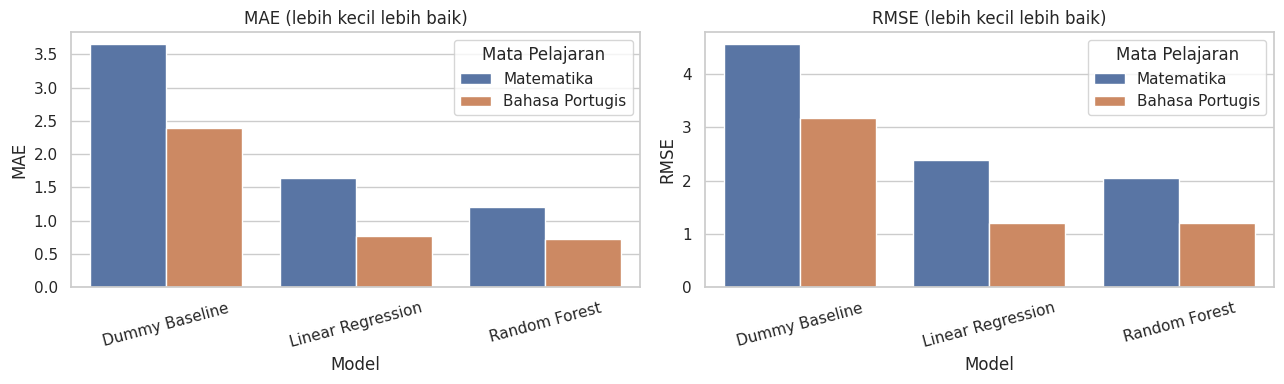

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=results_all, x="Model", y="MAE", hue="Mata Pelajaran", ax=axes[0])
axes[0].set_title("MAE (lebih kecil lebih baik)")
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=results_all, x="Model", y="RMSE", hue="Mata Pelajaran", ax=axes[1])
axes[1].set_title("RMSE (lebih kecil lebih baik)")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

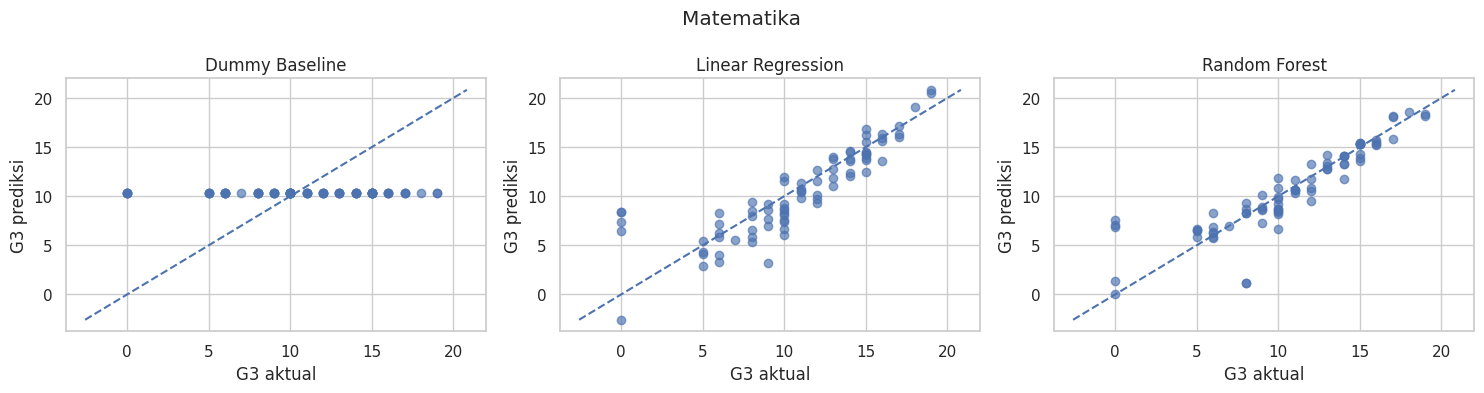

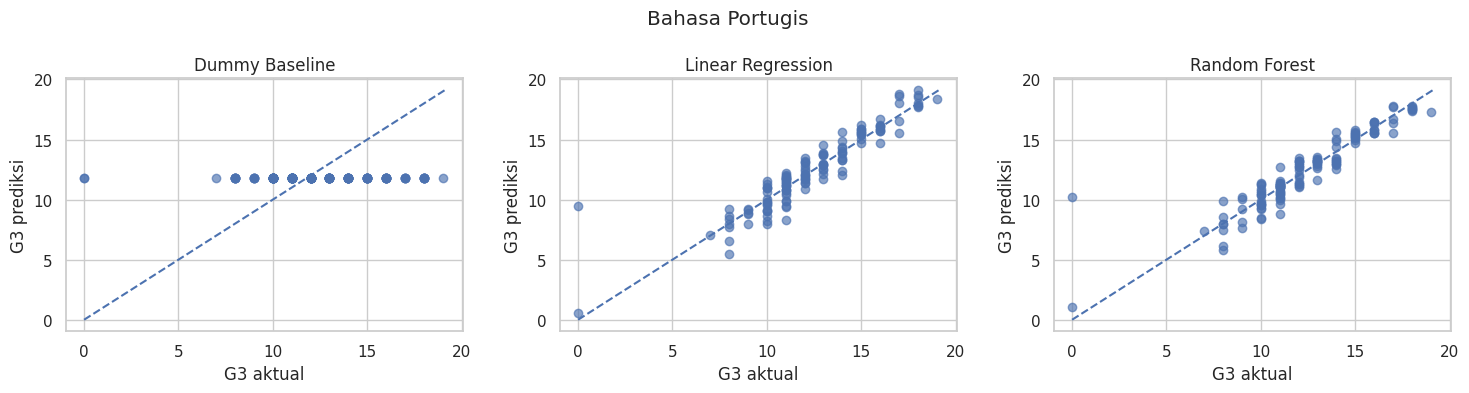

In [ ]:
def plot_actual_predicted(y_test, predictions, subject):
    low = min(float(y_test.min()), min(float(np.min(p)) for p in predictions.values()))
    high = max(float(y_test.max()), max(float(np.max(p)) for p in predictions.values()))
    fig, axes = plt.subplots(1, len(predictions), figsize=(5 * len(predictions), 4))
    for ax, (name, pred) in zip(axes, predictions.items()):
        ax.scatter(y_test, pred, alpha=0.65)
        ax.plot([low, high], [low, high], "--")
        ax.set_title(name)
        ax.set_xlabel("G3 aktual")
        ax.set_ylabel("G3 prediksi")
    fig.suptitle(subject)
    plt.tight_layout()
    plt.show()

plot_actual_predicted(mat_ready[3], preds_mat, "Matematika")
plot_actual_predicted(por_ready[3], preds_por, "Bahasa Portugis")

Matematika


,Fitur,Importance
14,numeric__G2,0.798769
12,numeric__absences,0.115475
36,categorical__reason_home,0.018275
0,numeric__age,0.009684
13,numeric__G1,0.004680
40,categorical__guardian_mother,0.003633
6,numeric__famrel,0.003553
11,numeric__health,0.003404
35,categorical__reason_course,0.003289
8,numeric__goout,0.002692


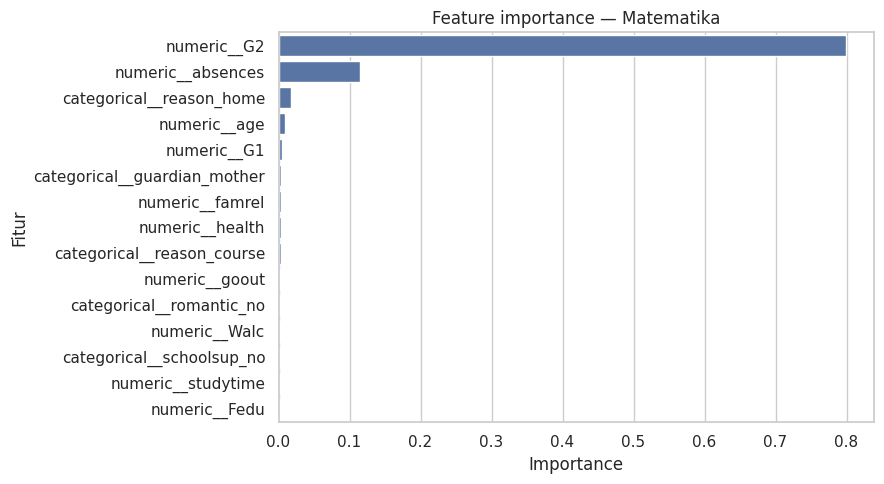

Bahasa Portugis


,Fitur,Importance
14,numeric__G2,0.848572
12,numeric__absences,0.034231
13,numeric__G1,0.014973
0,numeric__age,0.008566
1,numeric__Medu,0.006629
7,numeric__freetime,0.006337
6,numeric__famrel,0.005905
11,numeric__health,0.005332
37,categorical__reason_other,0.005242
9,numeric__Dalc,0.005228


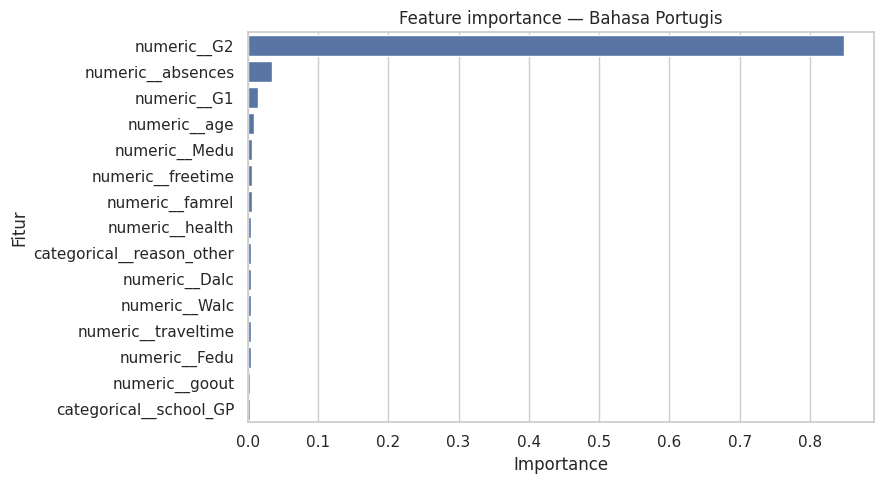

In [ ]:
def feature_importance(data, models, subject, top_n=15):
    prep = data[4]
    model = models["Random Forest"]
    names = prep.get_feature_names_out()
    importance = pd.DataFrame({
        "Fitur": names,
        "Importance": model.feature_importances_
    }).sort_values("Importance", ascending=False).head(top_n)
    print(subject)
    display(importance)
    plt.figure(figsize=(9, 5))
    sns.barplot(data=importance, x="Importance", y="Fitur")
    plt.title(f"Feature importance — {subject}")
    plt.tight_layout()
    plt.show()
    return importance

imp_mat = feature_importance(mat_ready, models_mat, "Matematika")
imp_por = feature_importance(por_ready, models_por, "Bahasa Portugis")

In [ ]:

OUT = Path("/content/training_outputs")
OUT.mkdir(exist_ok=True)

def save_subject(key, data, models, results):
    Xtr, Xte, ytr, yte, prep = data

    # Memilih model dengan MAE terkecil
    best_name = results.sort_values("MAE").iloc[0]["Model"]
    best_model = models[best_name]

    # Mengambil nama fitur asli sebelum preprocessing
    feature_names = prep.feature_names_in_.tolist()

    # Menyimpan model dan preprocessing dalam satu bundle
    bundle = {
        "preprocessor": prep,
        "model": best_model,
        "model_name": best_name,
        "target": "G3",
        "features": feature_names,
        "subject": key
    }

    joblib.dump(
        bundle,
        OUT / f"{key}_best_model_bundle.joblib"
    )

    # Membuat prediksi data testing
    pred = best_model.predict(Xte)

    # Menyimpan hasil prediksi
    prediction_df = pd.DataFrame({
        "nilai_aktual_G3": np.asarray(yte),
        "nilai_prediksi_G3": pred,
        "residual": np.asarray(yte) - pred
    })

    prediction_df.to_csv(
        OUT / f"{key}_best_predictions.csv",
        index=False
    )

    # Menyimpan metrik evaluasi
    results.to_csv(
        OUT / f"{key}_model_metrics.csv",
        index=False
    )

    # Menyimpan seluruh model pembanding
    for model_name, model in models.items():
        safe = model_name.lower().replace(" ", "_")

        joblib.dump(
            model,
            OUT / f"{key}_{safe}.joblib"
        )

# Simpan model Matematika
save_subject(
    "matematika",
    mat_ready,
    models_mat,
    results_mat
)

# Simpan model Bahasa Portugis
save_subject(
    "portugis",
    por_ready,
    models_por,
    results_por
)

# Simpan perbandingan seluruh model
results_all.to_csv(
    OUT / "all_model_comparison.csv",
    index=False
)

# Simpan feature importance
imp_mat.to_csv(
    OUT / "matematika_feature_importance.csv",
    index=False
)

imp_por.to_csv(
    OUT / "portugis_feature_importance.csv",
    index=False
)

print("SELURUH FILE BERHASIL DISIMPAN!")

for p in sorted(OUT.iterdir()):
    print(p.name)


SELURUH FILE BERHASIL DISIMPAN!
all_model_comparison.csv
matematika_best_model_bundle.joblib
matematika_best_predictions.csv
matematika_dummy_baseline.joblib
matematika_feature_importance.csv
matematika_linear_regression.joblib
matematika_model_metrics.csv
matematika_random_forest.joblib
portugis_best_model_bundle.joblib
portugis_best_predictions.csv
portugis_dummy_baseline.joblib
portugis_feature_importance.csv
portugis_linear_regression.joblib
portugis_model_metrics.csv
portugis_random_forest.joblib


In [ ]:
zip_path = Path("/content/training_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.iterdir():
        z.write(p, arcname=p.name)

from google.colab import files
files.download(str(zip_path))
print("Selesai. Simpan training_outputs.zip untuk tahap berikutnya.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Selesai. Simpan training_outputs.zip untuk tahap berikutnya.
